# 03. Random Forest Classification

training a Random Forest to predict the dataset's `burnout_risk_level`

We will hold out a stratified test set, use stratified five-fold cross-validation on the training data, evaluate the final model once on the test data, and save a separate model file so the existing artifact is preserved.

In [1]:
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from pathlib import Path

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    recall_score,
)
from sklearn.model_selection import StratifiedKFold, train_test_split

# Find the project root whether this notebook runs from the repository or notebooks folder.
dataset_relative_path = Path('data') / 'processed' / 'cognivault_cleaned_dataset.csv'
possible_project_roots = [Path.cwd(), Path.cwd().parent]
project_root = next(
    (path for path in possible_project_roots if (path / dataset_relative_path).exists()),
    None,
)

if project_root is None:
    raise FileNotFoundError(
        f'Could not find {dataset_relative_path} from the current folder: {Path.cwd()}'
    )

data_path = project_root / dataset_relative_path
df = pd.read_csv(data_path)
print(f'Loaded {len(df)} rows and {len(df.columns)} columns from {data_path}.')

Loaded 1900 rows and 16 columns from d:\Cognivault\data\processed\cognivault_cleaned_dataset.csv.


### 1. Choose the inputs and prediction target

The model receives exactly the nine agreed workload and lifestyle features listed below. The class to predict is `burnout_risk_level`. The score target (`burnout_risk_score`) and all profile/context fields are deliberately kept out of the inputs to prevent leakage and keep the feature contract consistent.

In [2]:

features = [
    'study_hours_outside_classes_per_day',
    'academic_tasks_per_week',
    'academic_workload',
    'time_pressure',
    'avg_sleep_hours',
    'wakes_up_tired',
    'physical_activity_days_per_week',
    'difficulty_concentrating',
    'academic_emotional_exhaustion',
]
target = 'burnout_risk_level'
score_target = 'burnout_risk_score'
profile_context_columns = [
    'institution',
    'degree',
    'year',
    'branch',
    'living_arrangement',
    'student_id',
    'data_source',
]

required_columns = features + [target, score_target]
missing_columns = [column for column in required_columns if column not in df.columns]
if missing_columns:
    raise ValueError(f'Missing required dataset columns: {missing_columns}')
if len(features) != 9 or len(set(features)) != 9:
    raise ValueError('The classifier must use exactly nine unique configured features.')
if target in features or score_target in features:
    raise ValueError('Target columns must never be included in model inputs.')
leaked_profile_columns = [column for column in profile_context_columns if column in features]
if leaked_profile_columns:
    raise ValueError(f'Profile/context columns leaked into model inputs: {leaked_profile_columns}')
if df[features].isna().any().any():
    raise ValueError('Missing values were found in the selected model features.')

class_labels = ['Low', 'Moderate', 'High', 'Critical']
unexpected_labels = sorted(set(df[target].dropna()) - set(class_labels))
if unexpected_labels:
    raise ValueError(f'Unexpected values in {target}: {unexpected_labels}')

X = df.loc[:, features].copy()
y = df[target].copy()

print(f'Input features ({len(features)}): {features}')
print(f'Prediction target: {target}')
print(f'Feature matrix shape: {X.shape}')
print(f'Target vector shape: {y.shape}')
print('Class counts in the full cleaned dataset:')
print(y.value_counts().reindex(class_labels, fill_value=0).to_string())

Input features (9): ['study_hours_outside_classes_per_day', 'academic_tasks_per_week', 'academic_workload', 'time_pressure', 'avg_sleep_hours', 'wakes_up_tired', 'physical_activity_days_per_week', 'difficulty_concentrating', 'academic_emotional_exhaustion']
Prediction target: burnout_risk_level
Feature matrix shape: (1900, 9)
Target vector shape: (1900,)
Class counts in the full cleaned dataset:
burnout_risk_level
Low         455
Moderate    687
High        553
Critical    205


### 2. Split into training and test data

We reserve 20% of the rows for a final test. Stratification keeps each risk-level category represented in similar proportions in both sets. The fixed seed makes the split reproducible. The test data stays untouched during cross-validation and model fitting.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42,
)

print(f'Training set: {len(X_train)} rows ({len(X_train) / len(X):.0%})')
print(f'Test set:     {len(X_test)} rows ({len(X_test) / len(X):.0%})')
print('Training class counts:')
print(y_train.value_counts().reindex(class_labels, fill_value=0).to_string())
print('Test class counts:')
print(y_test.value_counts().reindex(class_labels, fill_value=0).to_string())

Training set: 1520 rows (80%)
Test set:     380 rows (20%)
Training class counts:
burnout_risk_level
Low         364
Moderate    550
High        442
Critical    164
Test class counts:
burnout_risk_level
Low          91
Moderate    137
High        111
Critical     41


### 3. Cross-validate on the training set

Five-fold stratified cross-validation repeatedly trains on four-fifths of the training split and validates on the remaining fifth. Every row in the held-out test set is still kept out of this step. We summarize macro F1 and the recall for the High and Critical classes across the five validation folds.

In [4]:
cross_validator = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_macro_f1_scores = []
cv_high_recall_scores = []
cv_critical_recall_scores = []

for fold_number, (train_indices, validation_indices) in enumerate(
    cross_validator.split(X_train, y_train),
    start=1,
):
    X_fold_train = X_train.iloc[train_indices]
    y_fold_train = y_train.iloc[train_indices]
    X_fold_validation = X_train.iloc[validation_indices]
    y_fold_validation = y_train.iloc[validation_indices]

    fold_model = RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight='balanced',
        n_jobs=-1,
    )
    fold_model.fit(X_fold_train, y_fold_train)
    fold_predictions = fold_model.predict(X_fold_validation)

    fold_macro_f1 = f1_score(
        y_fold_validation,
        fold_predictions,
        labels=class_labels,
        average='macro',
        zero_division=0,
    )
    fold_high_recall = recall_score(
        y_fold_validation,
        fold_predictions,
        labels=['High'],
        average=None,
        zero_division=0,
    )[0]
    fold_critical_recall = recall_score(
        y_fold_validation,
        fold_predictions,
        labels=['Critical'],
        average=None,
        zero_division=0,
    )[0]

    cv_macro_f1_scores.append(fold_macro_f1)
    cv_high_recall_scores.append(fold_high_recall)
    cv_critical_recall_scores.append(fold_critical_recall)

    print(
        f'Fold {fold_number}: macro F1 = {fold_macro_f1:.4f}, '
        f'High recall = {fold_high_recall:.4f}, '
        f'Critical recall = {fold_critical_recall:.4f}'
    )

print('\nCross-validation mean (standard deviation):')
print(f'Macro F1:       {np.mean(cv_macro_f1_scores):.4f} ({np.std(cv_macro_f1_scores):.4f})')
print(f'High recall:    {np.mean(cv_high_recall_scores):.4f} ({np.std(cv_high_recall_scores):.4f})')
print(f'Critical recall:{np.mean(cv_critical_recall_scores):.4f} ({np.std(cv_critical_recall_scores):.4f})')

Fold 1: macro F1 = 0.8443, High recall = 0.8202, Critical recall = 0.8125
Fold 2: macro F1 = 0.8318, High recall = 0.8090, Critical recall = 0.8788
Fold 3: macro F1 = 0.8156, High recall = 0.7727, Critical recall = 0.7879
Fold 4: macro F1 = 0.8351, High recall = 0.7500, Critical recall = 0.9394
Fold 5: macro F1 = 0.8530, High recall = 0.7955, Critical recall = 0.8485

Cross-validation mean (standard deviation):
Macro F1:       0.8359 (0.0126)
High recall:    0.7895 (0.0253)
Critical recall:0.8534 (0.0530)


### 4. Fit the final model and evaluate the held-out test set

After cross-validation, we train one final Random Forest on the complete training split. Only then do we make test predictions. This gives one final evaluation on data that was not used to fit or select the model.

In [5]:
final_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight='balanced',
    n_jobs=-1,
)
final_model.fit(X_train, y_train)

# Make predictions once on the test data, after all training and cross-validation.
y_test_predictions = final_model.predict(X_test)
test_accuracy = accuracy_score(y_test, y_test_predictions)
test_macro_f1 = f1_score(
    y_test,
    y_test_predictions,
    labels=class_labels,
    average='macro',
    zero_division=0,
)
test_report = classification_report(
    y_test,
    y_test_predictions,
    labels=class_labels,
    target_names=class_labels,
    output_dict=True,
    zero_division=0,
)
per_class_metrics = pd.DataFrame(test_report).T.loc[
    class_labels,
    ['precision', 'recall', 'f1-score', 'support'],
]
test_high_recall = test_report['High']['recall']
test_critical_recall = test_report['Critical']['recall']

print(f'Test accuracy: {test_accuracy:.4f}')
print(f'Test macro F1: {test_macro_f1:.4f}')
print('\nPer-class test precision, recall, F1, and support:')
print(per_class_metrics.to_string(float_format=lambda value: f'{value:.4f}'))
print(f'\nTest High recall:     {test_high_recall:.4f}')
print(f'Test Critical recall: {test_critical_recall:.4f}')

Test accuracy: 0.7921
Test macro F1: 0.7844

Per-class test precision, recall, F1, and support:
          precision  recall  f1-score  support
Low          0.9205  0.8901    0.9050  91.0000
Moderate     0.7956  0.7956    0.7956 137.0000
High         0.7094  0.7477    0.7281 111.0000
Critical     0.7368  0.6829    0.7089  41.0000

Test High recall:     0.7477
Test Critical recall: 0.6829


**How to read these metrics:** Accuracy is the fraction of all test rows classified correctly. Macro F1 averages the F1 score of each class equally. Per-class recall answers: of the rows truly in that class, what fraction did the model find? These numbers measure agreement with the dataset's labels only; they do not measure real-world burnout or diagnose anyone.

### 5. Read the confusion matrix

Rows show the true test labels and columns show the predicted labels. The printed table gives the exact counts, and the heatmap makes patterns of correct predictions and errors easier to see.

Confusion matrix counts (rows = actual, columns = predicted):
Predicted  Low  Moderate  High  Critical
Actual                                  
Low         81        10     0         0
Moderate     7       109    21         0
High         0        18    83        10
Critical     0         0    13        28


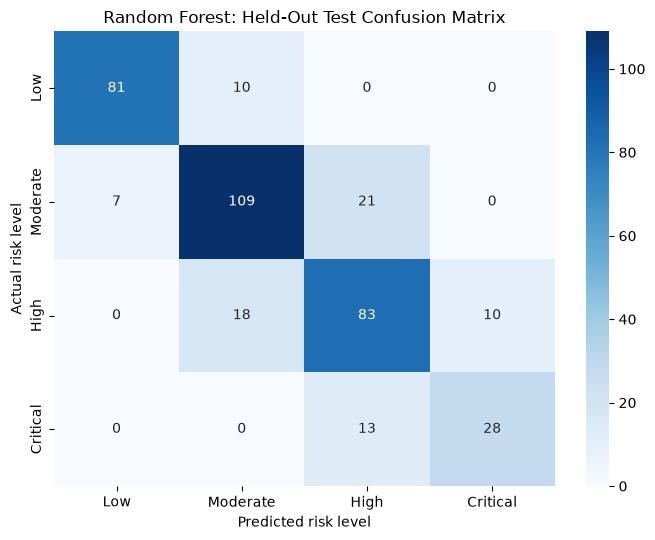

In [6]:
confusion_counts = confusion_matrix(
    y_test,
    y_test_predictions,
    labels=class_labels,
)
confusion_table = pd.DataFrame(
    confusion_counts,
    index=pd.Index(class_labels, name='Actual'),
    columns=pd.Index(class_labels, name='Predicted'),
)
print('Confusion matrix counts (rows = actual, columns = predicted):')
print(confusion_table.to_string())

plt.figure(figsize=(7, 5.5))
sns.heatmap(
    confusion_table,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_labels,
    yticklabels=class_labels,
)
plt.title('Random Forest: Held-Out Test Confusion Matrix')
plt.xlabel('Predicted risk level')
plt.ylabel('Actual risk level')
plt.tight_layout()
plt.show()

The diagonal cells are correct predictions. Off-diagonal cells show which labels the model confused. Review these counts alongside per-class recall; a strong overall accuracy can hide weaker performance for a particular class.

### 6. Optional diagnostic: feature importance

A Random Forest can estimate how much each feature contributed to its tree decisions. These values describe this fitted model and are not causal explanations.

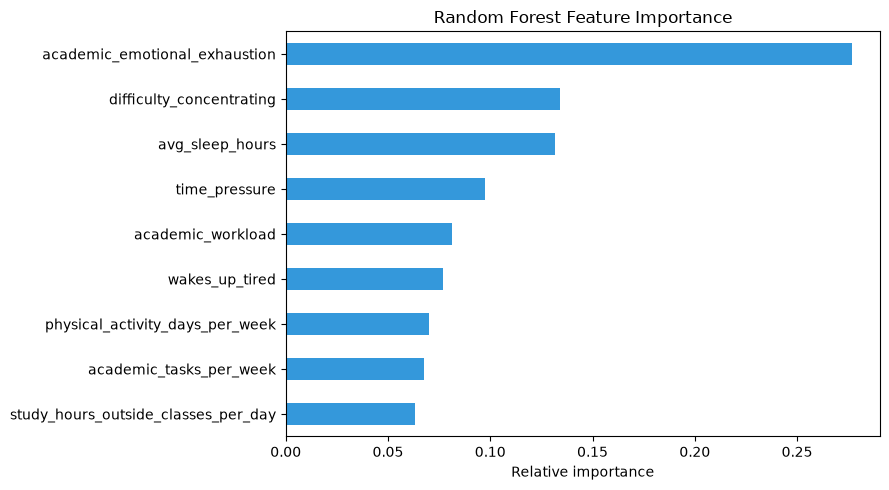

In [7]:
feature_importances = pd.Series(
    final_model.feature_importances_,
    index=features,
    name='Importance',
).sort_values()

plt.figure(figsize=(9, 5))
feature_importances.plot(kind='barh', color='#3498db')
plt.title('Random Forest Feature Importance')
plt.xlabel('Relative importance')
plt.tight_layout()
plt.show()

Feature importance is a model diagnostic, not evidence that changing a feature will cause a change in a student's wellbeing. 

### 7. Save and reload the model

This notebook saves the trained classifier to `models/random_forest_model.joblib`, then reloads it from the same path, checks its feature order, and makes one sample prediction.

In [8]:
models_directory = project_root / 'models'
models_directory.mkdir(parents=True, exist_ok=True)
model_path = models_directory / 'random_forest_model.joblib'

joblib.dump(final_model, model_path)
print(f'Saved model to: {model_path}')

reloaded_model = joblib.load(model_path)
if list(reloaded_model.feature_names_in_) != features:
    raise ValueError('The saved model feature order does not match the notebook feature contract.')

sample_features = X_test.iloc[[0]]
sample_prediction = reloaded_model.predict(sample_features)[0]
print(f'Reloaded model prediction for one held-out example: {sample_prediction}')
print('Saved-model reload and prediction check passed.')

Saved model to: d:\Cognivault\models\random_forest_model.joblib
Reloaded model prediction for one held-out example: Moderate
Saved-model reload and prediction check passed.
